In [11]:
import networkx as nx
from scipy.io import mmread
#Data Import
G = nx.from_scipy_sparse_array(mmread("socfb-Cornell5/socfb-Cornell5.mtx"))

/tmp/ipykernel_62072/1418765487.py:4: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  G = nx.from_scipy_sparse_array(mmread("socfb-Cornell5/socfb-Cornell5.mtx"))


In [13]:
#Simple Network Stats
import numpy as np
N= G.number_of_nodes()
L= G.number_of_edges()
deg = dict(G.degree())
cc = list(dict(nx.clustering(G)).values())

k_avg= np.mean(list(deg.values()))
average_clustering = np.mean(cc)

print("N: ", N)
print("L: ", L)
print("Average Degree: ", k_avg)
print("Average Clustering: ", average_clustering)

G_null = G.copy() #Config Null Model: w/ no self-loops or multi-path
nx.double_edge_swap(G_null, nswap=10 * G_null.number_of_edges(),
                    max_tries=100 * G_null.number_of_edges(), seed=42)

N_null= G_null.number_of_nodes()
L_null= G_null.number_of_edges()
deg_null = dict(G_null.degree())
cc_null = list(dict(nx.clustering(G_null)).values())

k_avg_null= np.mean(list(deg_null.values()))
average_clustering_null = np.mean(cc_null)

print("N_null: ", N_null)
print("L_null: ", L_null)
print("Average Degree (Null Model): ", k_avg_null)
print("Average Clustering (Null Model): ", average_clustering_null)

N:  18660
L:  790777
Average Degree:  84.75637727759914
Average Clustering:  0.21905095283303203
N_null:  18660
L_null:  790777
Average Degree (Null Model):  84.75637727759914
Average Clustering (Null Model):  0.01801409137021733


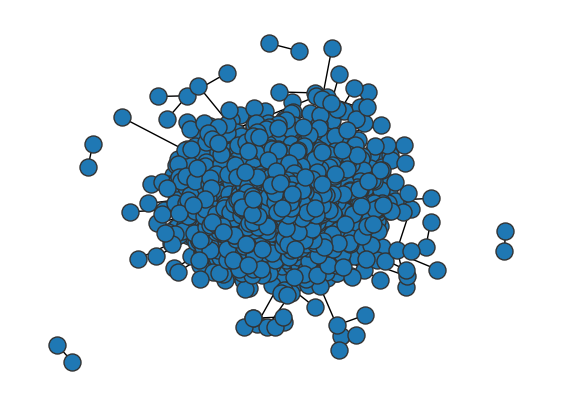

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

visual = nx.draw(G, pos=pos, node_size=150, edgecolors='.2', ax=ax)

In [14]:
#Community Detection
import networkx as nx
import numpy as np
from collections import defaultdict
from random import shuffle
import matplotlib.pyplot as plt
import community

partition = community.best_partition(G)#Louvain

# Output the best modularity score
print("Best Modularity: ", community.modularity(partition, G))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected: ",len(np.unique(list(partition.values()))))

# Storing and showing partition as dictionary
G_parts = dict(partition)
print("Partition Dictionary: ", G_parts)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition.values())))))
colors_nodes = [colors_sns[partition[node]] for node in G.nodes()]

partition_null = community.best_partition(G_null)#Louvain

# Output the best modularity score
print("Best Modularity (Null Model): ", community.modularity(partition_null, G_null))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected (Null Model): ",len(np.unique(list(partition_null.values()))))

# Storing and showing partition as dictionary
G_parts_null = dict(partition_null)
print("Partition Dictionary (Null Model): ", G_parts_null)
colors_sns_null = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition_null.values())))))
colors_nodes_null = [colors_sns[partition_null[node]] for node in G_null.nodes()]

Best Modularity:  0.4669792991062554
Number of Communities Detected:  29
Partition Dictionary:  {0: 0, 1: 1, 2: 2, 3: 3, 4: 0, 5: 0, 6: 2, 7: 1, 8: 3, 9: 16, 10: 3, 11: 1, 12: 16, 13: 1, 14: 0, 15: 2, 16: 1, 17: 1, 18: 16, 19: 1, 20: 16, 21: 1, 22: 1, 23: 3, 24: 1, 25: 5, 26: 2, 27: 3, 28: 0, 29: 1, 30: 1, 31: 0, 32: 15, 33: 1, 34: 3, 35: 1, 36: 7, 37: 1, 38: 16, 39: 2, 40: 16, 41: 0, 42: 2, 43: 16, 44: 16, 45: 1, 46: 0, 47: 16, 48: 0, 49: 8, 50: 8, 51: 1, 52: 1, 53: 2, 54: 5, 55: 1, 56: 2, 57: 3, 58: 3, 59: 3, 60: 1, 61: 8, 62: 7, 63: 2, 64: 2, 65: 3, 66: 0, 67: 1, 68: 8, 69: 1, 70: 3, 71: 2, 72: 5, 73: 5, 74: 1, 75: 2, 76: 8, 77: 8, 78: 16, 79: 16, 80: 1, 81: 0, 82: 3, 83: 1, 84: 16, 85: 2, 86: 1, 87: 2, 88: 0, 89: 1, 90: 2, 91: 16, 92: 1, 93: 3, 94: 8, 95: 0, 96: 0, 97: 16, 98: 1, 99: 10, 100: 3, 101: 1, 102: 0, 103: 0, 104: 7, 105: 1, 106: 16, 107: 1, 108: 7, 109: 16, 110: 16, 111: 1, 112: 1, 113: 2, 114: 0, 115: 3, 116: 1, 117: 8, 118: 1, 119: 1, 120: 8, 121: 1, 122: 1, 123: 0, 12

Not great modularity from Louvain

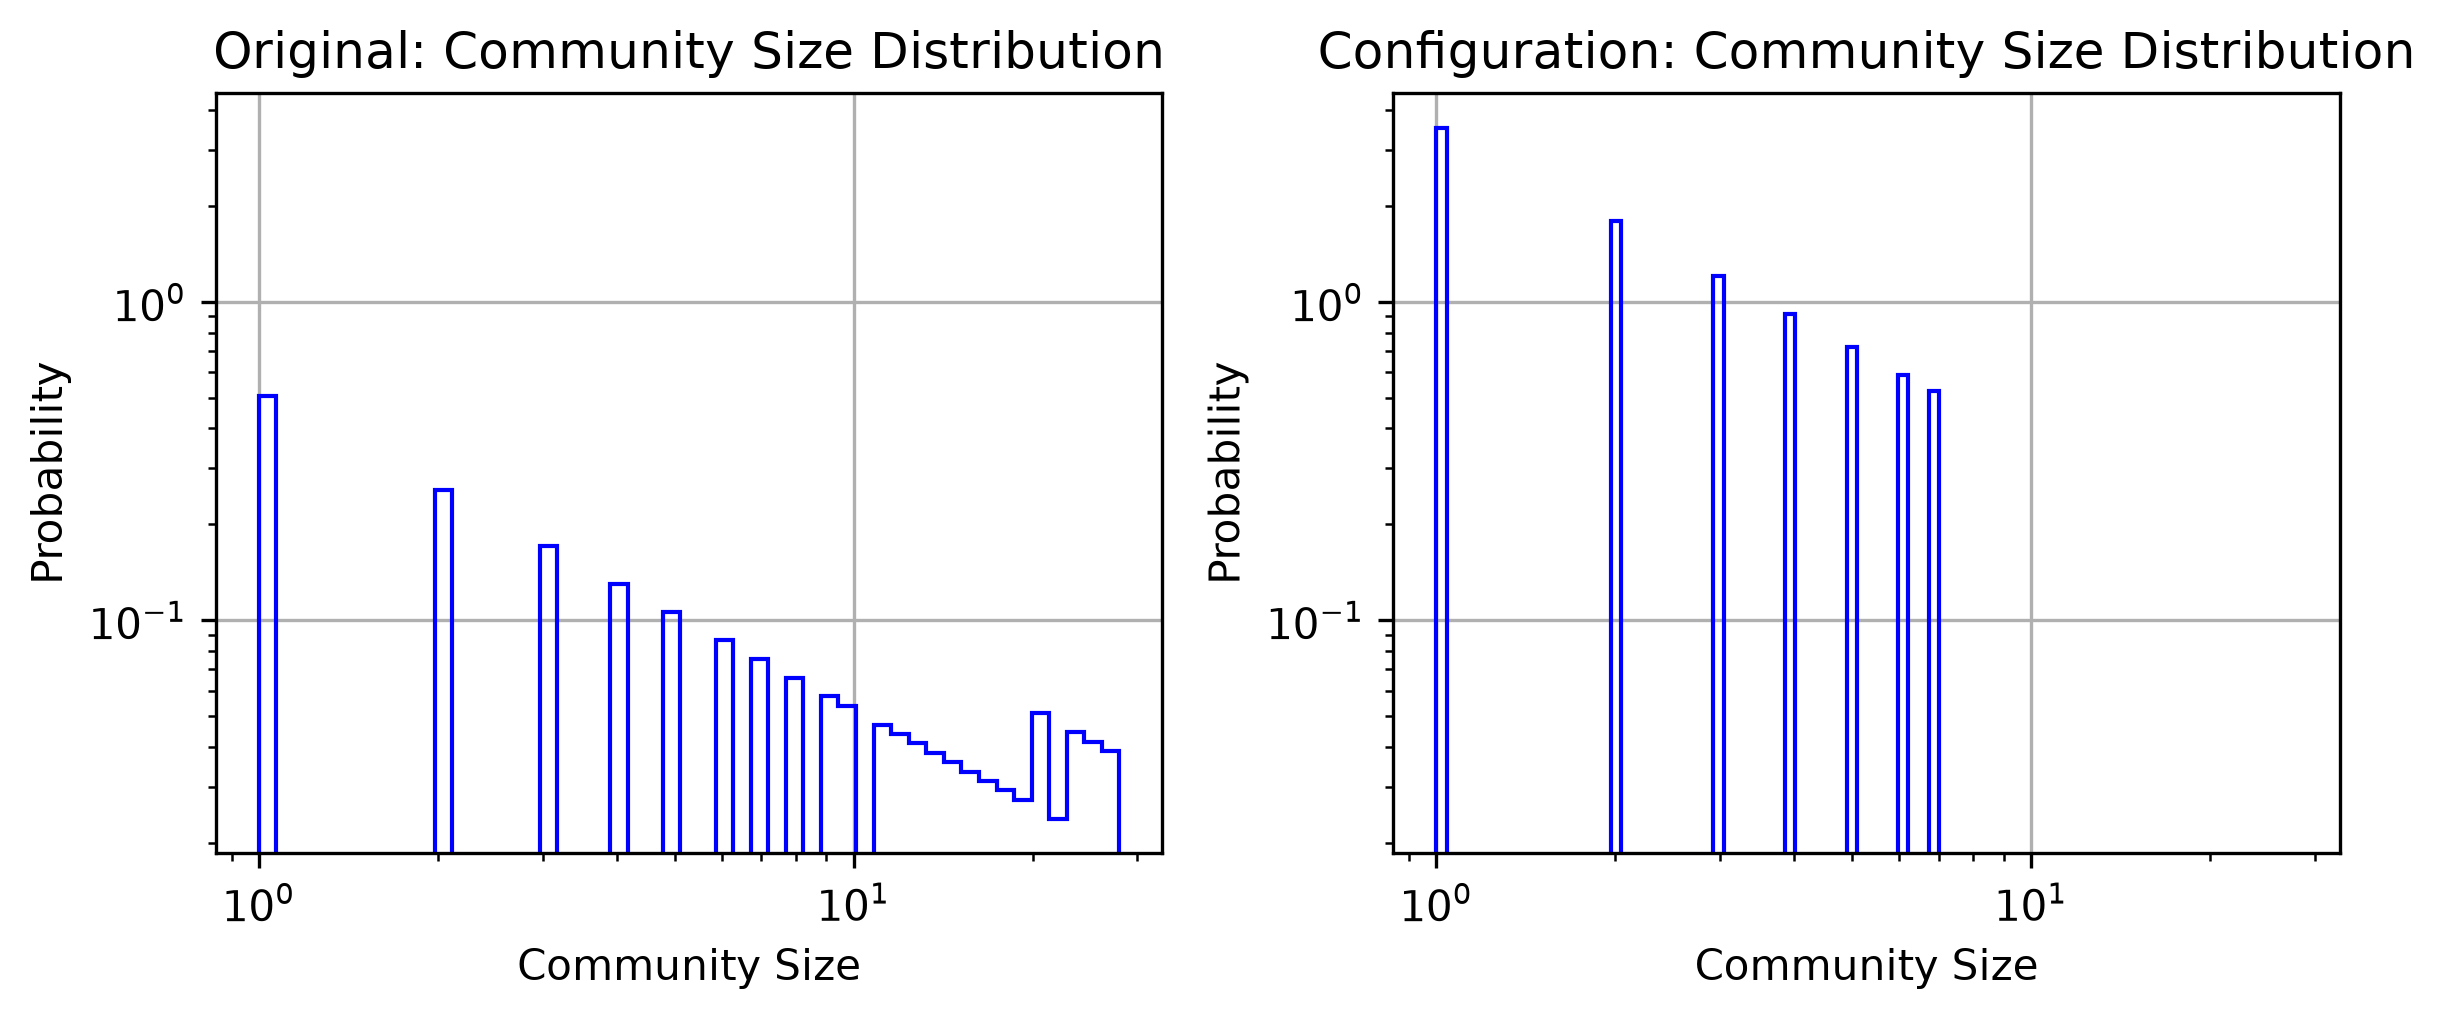

In [ ]:
from collections import Counter

community_sizes = Counter(G_parts.values())
null_community_sizes = Counter(G_parts_null.values())

fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)

# Plotting the community size distribution of the original dataset
org_bins = np.geomspace(1,np.max(list(community_sizes)))#Defining the smallest community as an isolated node of 1
ax[0].hist(list(community_sizes),bins=org_bins, density=True,color = 'b',histtype='step')
ax[0].loglog()
ax[0].set_title("Original: Community Size Distribution")
ax[0].set_xlabel("Community Size")
ax[0].set_ylabel("Probability")
ax[0].grid(True)
# Plotting the community size distribution of the Chung Lu Null Model of the dataset
null_bins = np.geomspace(1,np.max(list(null_community_sizes)))
ax[1].hist(list(null_community_sizes),bins=null_bins,density=True,color = 'b',histtype='step')
ax[1].loglog()
ax[1].set_title("Configuration: Community Size Distribution")
ax[1].set_xlabel("Community Size")
#ax[1].set_ylabel("Probability")
ax[1].tick_params(labelleft=True)
ax[1].grid(True)

plt.tight_layout()

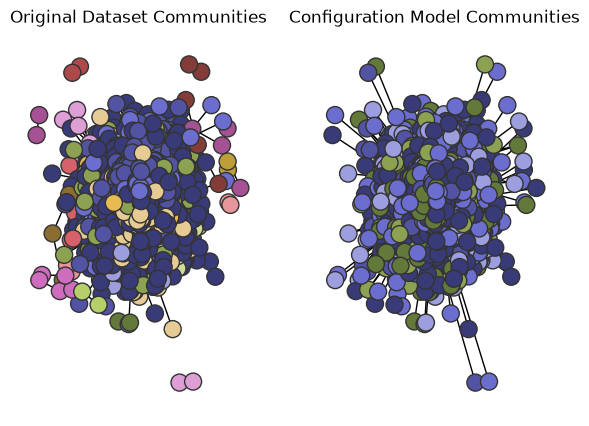

In [ ]:
#Community Visualization
fig, ax = plt.subplots(1,2,figsize=(7,5),dpi=100)
pos = nx.fruchterman_reingold_layout(G)

nx.draw(G, pos=pos,label="Original Dataset Communities", node_size=150, edgecolors='.2', node_color=colors_nodes, ax=ax[0])
nx.draw(G_null, pos=pos,label="Configuration Model Communities", node_size=150, edgecolors='.2', node_color=colors_nodes_null, ax=ax[1])
ax[0].set_title("Original Dataset Communities")
ax[1].set_title("Configuration Model Communities")
plt.show()

In [27]:
#Centrality
closeness_centrality = nx.closeness_centrality(G)
#betweeness_centrality = nx.betweenness_centrality(G,k=2000)
#eigenvector_centrality = nx.eigenvector_centrality_numpy(G)


# Sorting using a for loop
sorted_dict = {}
for key in sorted(closeness_centrality, key=closeness_centrality.get, reverse=True):
    sorted_dict[key] = closeness_centrality[key]

print("Most Central Nodes by Closeness: ", sorted_dict)
#print("Betweeness Centrality: ", betweeness_centrality)
#print("Eigenvector Centrality: ", eigenvector_centrality)


Most Central Nodes by Closeness:  {17026: 0.5286074796057719, 9650: 0.5023271564104484, 4481: 0.5003657335565501, 8200: 0.491160199720401, 16111: 0.49108231402126196, 12796: 0.48057835494575024, 10632: 0.47286121683731996, 4451: 0.46127504879654657, 10092: 0.4547387855319862, 17667: 0.4516329180793955, 11867: 0.4480932190807748, 6713: 0.4477800635150976, 2633: 0.44610298462552794, 2007: 0.44591028355225554, 7600: 0.44132440718292015, 5671: 0.4404456708375208, 9671: 0.43978891161236655, 1174: 0.43973687174588777, 18050: 0.4394664628467276, 8016: 0.43925868219717, 3248: 0.4389059056483403, 850: 0.438315755699719, 16525: 0.4379644914821687, 16507: 0.4375313533866084, 12672: 0.4369551668615955, 3514: 0.43689352258693837, 10491: 0.43685243606579416, 12074: 0.43681135727167447, 14571: 0.43665738057534104, 16739: 0.4361244341185891, 13498: 0.4360220935262815, 13274: 0.43581755636501673, 17499: 0.43561321100978756, 5963: 0.4351949015276019, 16792: 0.43480791677873565, 1596: 0.4347367051688657,

In [28]:

#Centrality
closeness_centrality_null = nx.closeness_centrality(G_null)
#betweeness_centrality = nx.betweenness_centrality(G,k=2000)
#eigenvector_centrality = nx.eigenvector_centrality_numpy(G)


# Sorting using a for loop
sorted_dict_null = {}
for key in sorted(closeness_centrality_null, key=closeness_centrality_null.get, reverse=True):
    sorted_dict_null[key] = closeness_centrality_null[key]

print("Most Central Nodes by Closeness (in Null Model): ", sorted_dict_null)
#print("Betweeness Centrality: ", betweeness_centrality)
#print("Eigenvector Centrality: ", eigenvector_centrality)

KeyboardInterrupt: 

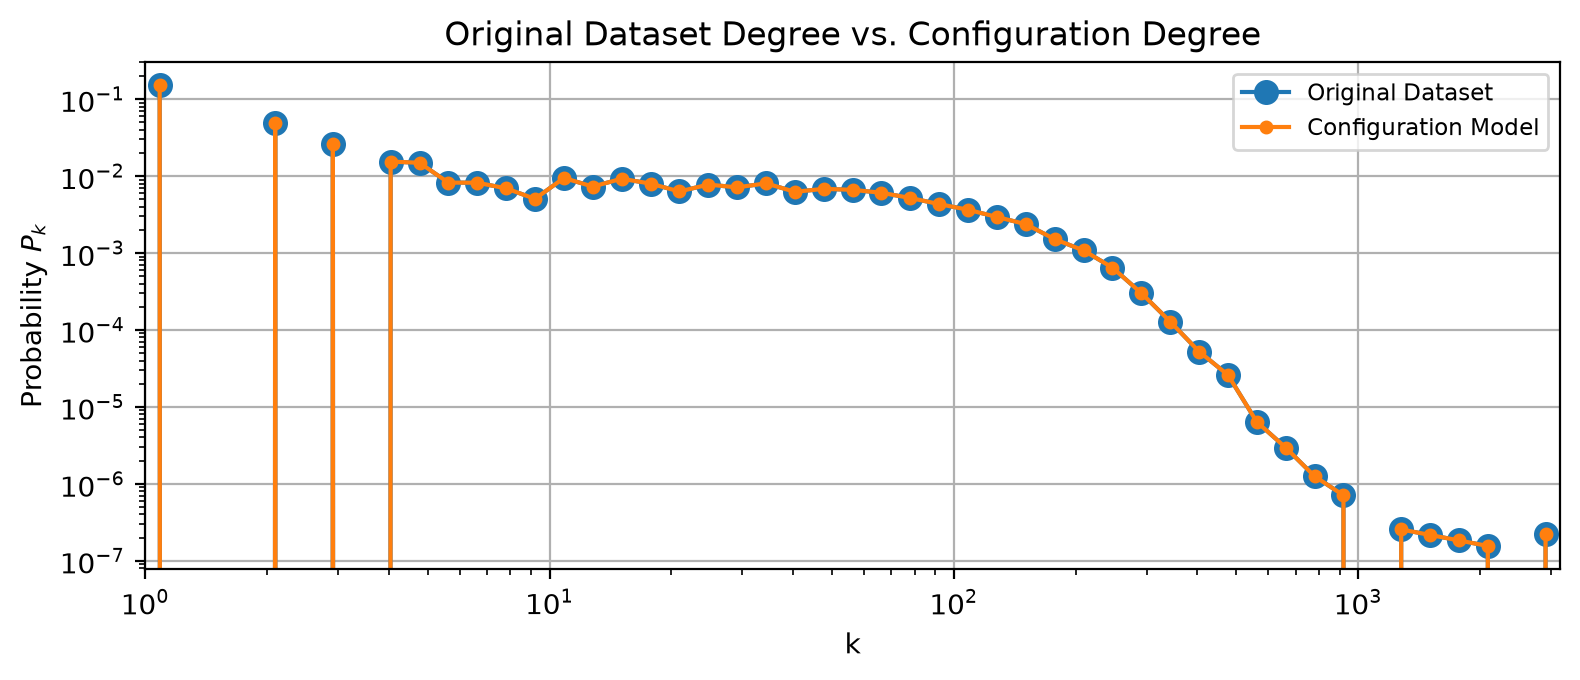

In [23]:
actual_deg_sequence = list(deg.values())
actual_deg_sequence_null = list(deg_null.values())

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

bins = np.geomspace(1,np.max(actual_deg_sequence))
counts, bin_edges = np.histogram(actual_deg_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(1,np.max(actual_deg_sequence_null))
counts_null, bin_edges_null = np.histogram(actual_deg_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=4, label="Configuration Model")

#LEGACY:
#ax[1].hist(actual_deg_sequence_null,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
#ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#handles, labels = ax.get_legend_handles_labels()
#ax[1].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Degree vs. Configuration Degree")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_{k}$")
true_min=min(min(actual_deg_sequence), min(actual_deg_sequence_null))
true_max=max(max(actual_deg_sequence), max(actual_deg_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()


Degree distribution looks super strange. The tails appear to trace to one another a power law, but the whole middle portion is decidedly more log-normal. The region from roughly k=4 to 100 is roughly the same probability. Is this just a binning issue? Perhaps this is reflecting an artifact of facebook? For instance, one hypothesis could be that users on facebook, by the nature of the platform itself, may seek out some "minimum" follower count, e.g., 100-200 followers. And as such, it is of similar prevalence that we see users up to the 100 count, all the way down to the new accounts. rarely used accounts, or otherwise just naturally low degree account of the k=1-10 variety. It could also reflect just a feasibility limit, like that most people just don't know, or otherwise bother to get or maintain a follower account above ~200 or so. Similarly, there could be algorithmic constraints, applied 'soft-caps' or limits placed via Facebook that discourage followings above this number. 

In [ ]:
centrality_sequence = list(sorted_dict.values())
centrality_sequence_null = list(sorted_dict_null.values())
#---Plotting the Centrality
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning

centrality_sequence=np.asarray(centrality_sequence)
centrality_sequence_min= np.amin(centrality_sequence[centrality_sequence != np.amin(centrality_sequence)])
centrality_sequence_null=np.asarray(centrality_sequence_null)
centrality_sequence_null_min= np.amin(centrality_sequence_null[centrality_sequence_null != np.amin(centrality_sequence_null)])

bins = np.geomspace(centrality_sequence_min,np.max(centrality_sequence))
counts, bin_edges = np.histogram(centrality_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(centrality_sequence_null_min,np.max(centrality_sequence_null))
counts_null, bin_edges_null = np.histogram(centrality_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Centrality vs. Configuration Centrality")
ax.set_xlabel("Closeness Centrality")
ax.set_ylabel("Probability $P_{Cen_{closeness}}$")
true_min=min(min(centrality_sequence_min), min(centrality_sequence_null_min))
true_max=max(max(centrality_sequence), max(centrality_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'sorted_dict_null' is not defined

/tmp/ipykernel_62072/4244711198.py:33: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(true_min,true_max)


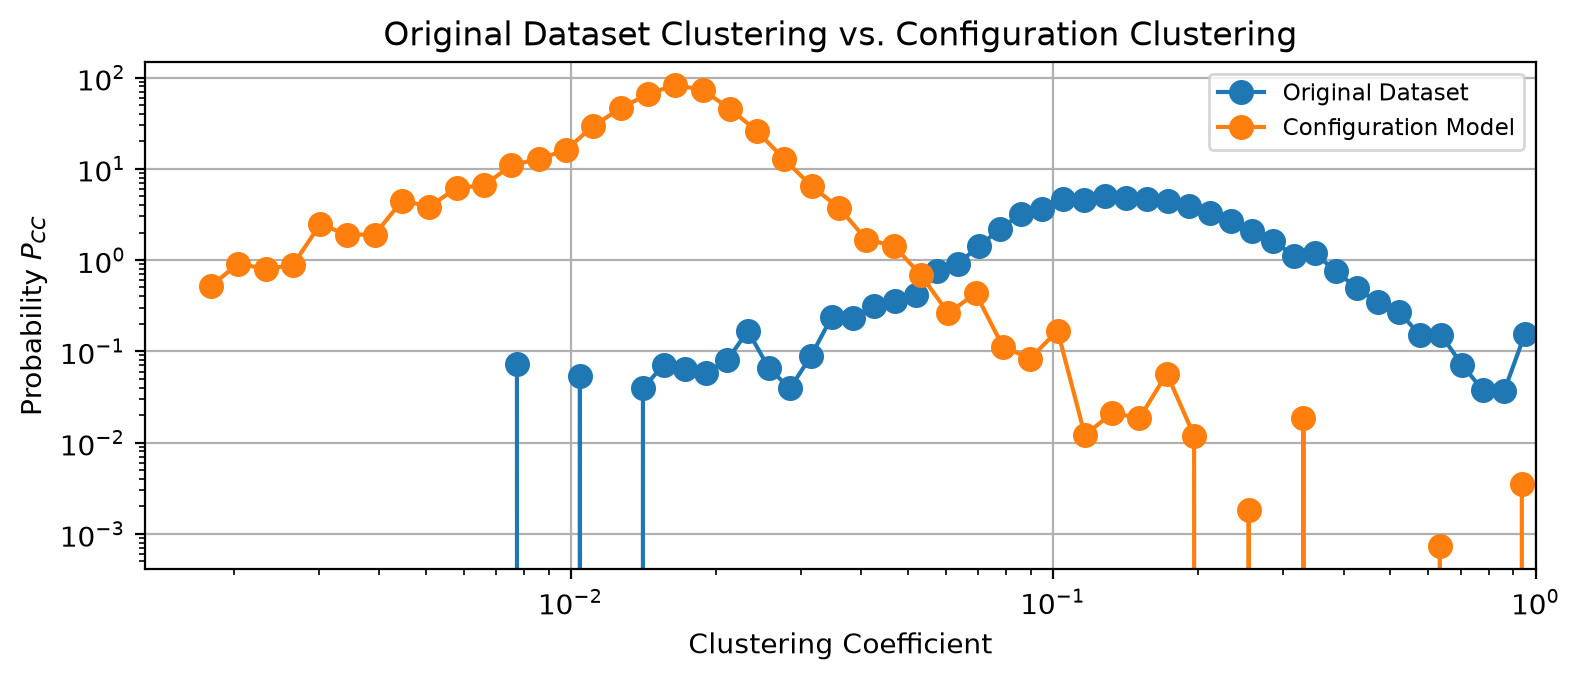

In [29]:
#---Plotting the Average Clustering Coefficient 'CC'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning
cc=np.asarray(cc)
cc_min= np.amin(cc[cc != np.amin(cc)])
cc_null=np.asarray(cc_null)
cc_null_min= np.amin(cc_null[cc_null != np.amin(cc_null)])

bins = np.geomspace(cc_min,np.max(cc))
counts, bin_edges = np.histogram(cc, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(cc_null_min,np.max(cc_null))
counts_null, bin_edges_null = np.histogram(cc_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Clustering vs. Configuration Clustering")
ax.set_xlabel("Clustering Coefficient")
ax.set_ylabel("Probability $P_{CC}$")
true_min=min(min(cc), min(cc_null))
true_max=max(max(cc), max(cc_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()